###  This notebook calculates 0-D RE evolution during a Disruption

 Loading Modules

In [42]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [43]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp
importlib.reload(RE)

<module 'RE' from '/Users/rishabhdatta/MIT Dropbox/Rishabh Datta/Rishabh_EP_Group/Code/RE_Solver/RE.py'>

## Instantiate solver and define settings

In [44]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.005
Zeff_scale [-] =1.0
device [-] = SPARC


In [52]:
# Change solver settings
solver.T0 = 20e3 # Initial temperature [eV]
solver.k = 1.7 # Elongation
solver.Ir0 = 1 # Initial RE Current [A]
solver.iCompton = 1 # Turn on activated sources
solver.iTritium = 1
solver.iAvalanche = 1
solver.iDreicer = 1

# Impurities (approx. baseline MGI of Ne + D2; full assimilation)
solver.n_imp = 0.5 * solver.ni
solver.nD = 18 * solver.n_imp

solver.device='SPARC'

solver.display()


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.700
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1
Init. Temp. T0 [eV] = 2e+04
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001
Init. Vloop V0 [V] = 0
Final Vloop Vf [V] = 0

 Impurity Settings:
Added D density [per cubic m] = 2.7e+21
Added Impurity density [per cubic m] = 1.5e+20
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 1, iCompton = 1
Secondary: iAvalanche = 1

 Other Settings: 

tstart [s] = 0
tmax [s] = 0.02
Zeff_scale [-] =1.0
device [-] = SPARC


## Solve

In [53]:
# solve
solver.tmax = 20e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

Here, we will plot  𝐼𝑝 and  𝐼_𝑅𝐸 as a function of time

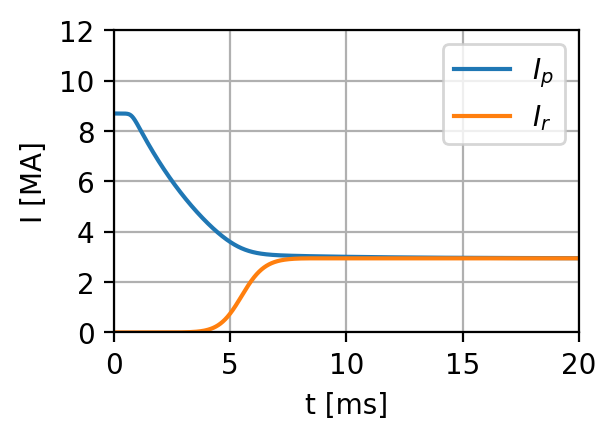

In [54]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,12])
plt.yticks(np.arange(0,13,2))
plt.xlim([0,solver.tmax*1e3])

plt.legend()


We can also plot the RE beam energy as a function of time

Plateau Energy [MJ] = 2.303
Average RE Energy [MeV] = 20.178


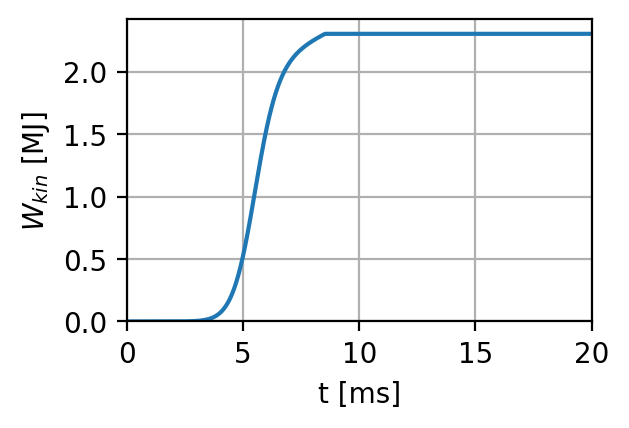

In [55]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


## Show detailed results

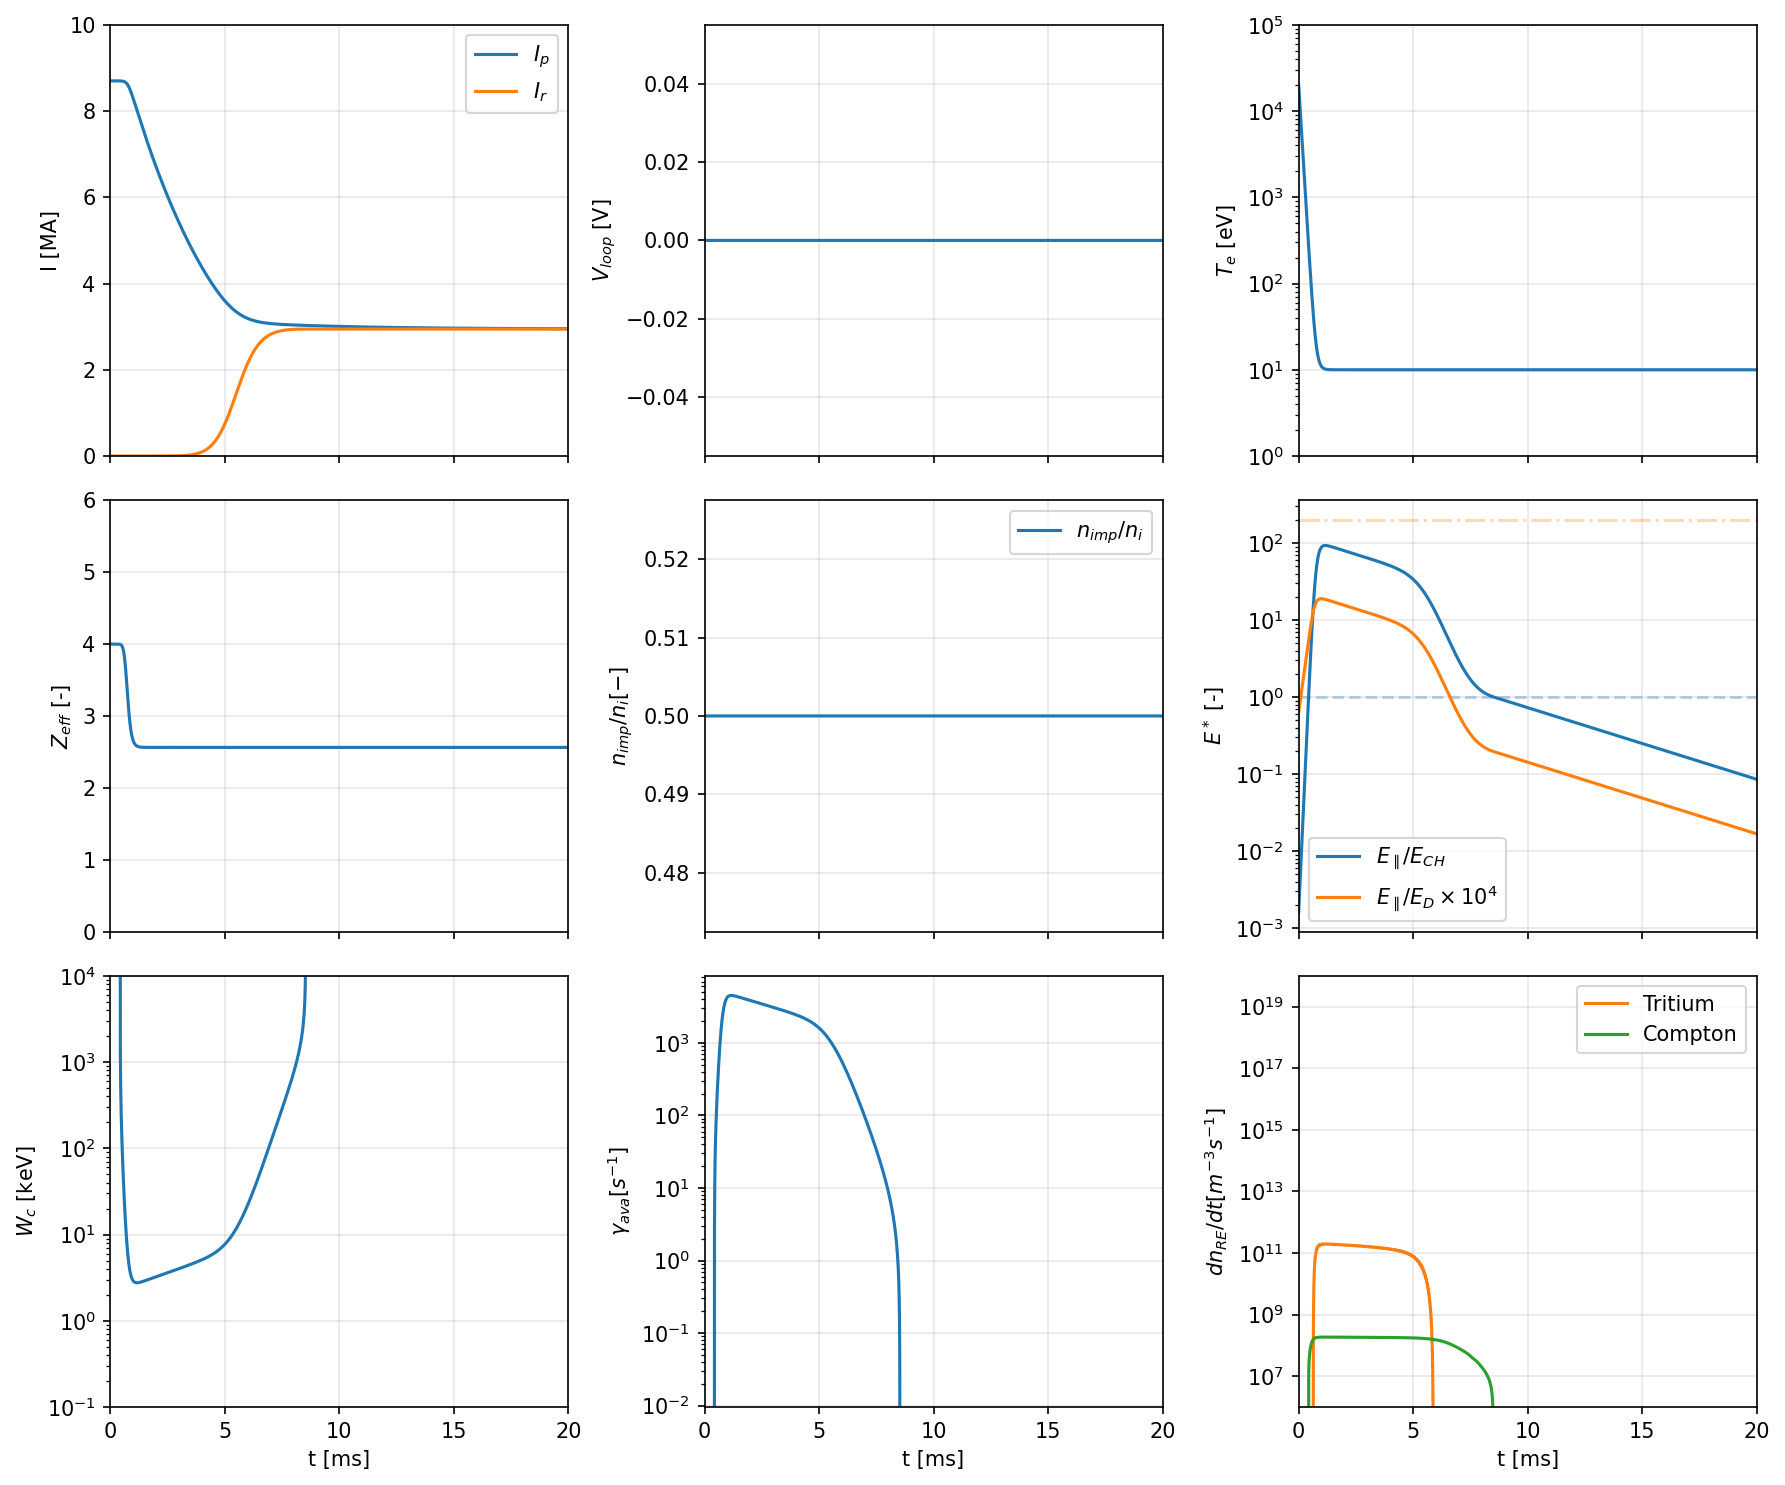

In [56]:
d = solver.diag

fig, axs = plt.subplots(3, 3, sharex=True, figsize=(12, 10), dpi=150)

# ==========================================
# ROW 0: Currents, External Loop Voltage, & Te
# ==========================================
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()
axs[0, 0].set_ylim([0, 10])

axs[0, 1].plot(d['t'] * 1e3, d['Vloop'])
axs[0, 1].set_ylabel('$V_{loop}$ [V]')

axs[0, 2].plot(d['t'] * 1e3, d['Te'])
axs[0, 2].set_ylabel('$T_e$ [eV]')
axs[0, 2].set_ylim([1, 10e4])
axs[0, 2].set_yscale('log')

# ==========================================
# ROW 1: Zeff, Impurities, & E-field
# ==========================================
axs[1, 0].plot(d['t'] * 1e3, d['Zeff'])
axs[1, 0].set_ylabel('$Z_{eff}$ [-]')
axs[1, 0].set_ylim([0, 6])

# MOVED: nimp/ni now placed directly after Zeff
axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

# SHIFTED: E* fields moved to row 1, col 2
axs[1, 2].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[1, 2].axhline(1, linestyle='--', alpha=0.3,color='tab:blue')
axs[1, 2].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[1, 2].axhline(2e-2 * 1e4, linestyle='-.', alpha=0.3,color='tab:orange')
axs[1, 2].set_ylabel('$E^*$ [-]')
axs[1, 2].set_yscale('log')
axs[1, 2].legend()

# ==========================================
# ROW 2: Critical Energy & RE Sources
# ==========================================
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[2, 0].plot(d['t'] * 1e3, Wc / 1e3)
axs[2, 0].set_ylabel('$W_c$ [keV]')
axs[2, 0].set_yscale('log')
axs[2, 0].set_ylim([1e-1, 1e4])

axs[2, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[2, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[2, 1].set_yscale('log')

# axs[2, 2].plot(d['t'] * 1e3, d['SD'], label='Dreicer',color='tab:blue')
axs[2, 2].plot(d['t'] * 1e3, d['ST'], label='Tritium',color='tab:orange')
axs[2, 2].plot(d['t'] * 1e3, d['SC'], label='Compton',color='tab:green')
axs[2, 2].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 2].set_yscale('log')
axs[2, 2].set_ylim([1e6, 1e20])
axs[2, 2].legend()

# ==========================================
# Global Formatting
# ==========================================
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])

# Apply X-axis labels to the bottom row (Row 2)
for ax in axs[2, :]:
    ax.set_xlabel('t [ms]')



fig.set_facecolor('w')
plt.tight_layout()
plt.show()

In [57]:
seedT = np.max(d['ST'])/np.max(d['gamma_ava']) * const.c * const.e * np.pi * solver.a**2 * solver.k # A
seedC = np.max(d['SC'])/np.max(d['gamma_ava']) * const.c * const.e * np.pi * solver.a**2 * solver.k # A


print('Tritium = %1.3g A'%seedT)
print('Compton = %1.3g A'%seedC)

Tritium = 0.00363 A
Compton = 3.45e-06 A


# Hot-Tail Seed

In [10]:

# Initiate arrays
nht = np.zeros_like(d['t'])
nht_rate = np.zeros_like(d['t'])
dt = np.diff(d['t'])[0]

# Caluclate
for ii in range(1,d['t'].shape[0]):
    T = d['Te'][ii] # eV
    nht_rate[ii], nht[ii] = RE.get_HT_rate(ne=d['ne'][0], # electron density
                                           T=T, # temperature
                                           t=d['t'][ii], # time
                                           T0=solver.T0, # initial temperature
                                           E0=d['Epar'][0], # initial E-field
                                           nht=nht[ii-1],
                                           dt=dt)

Iht = 0.000569 kA


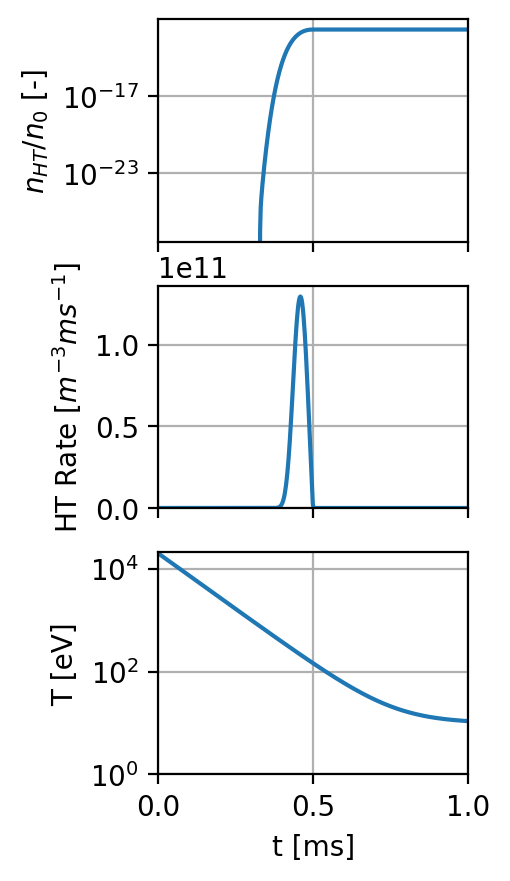

In [11]:
# Plot
fig, axs = plt.subplots(3,1,sharex=True,figsize=(2,5),dpi=200)
axs[0].plot(t*1e3,nht/d['ne'][0],'-')
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
# axs[0].set_ylim([1e-20,1e0])
axs[0].grid()

axs[1].plot(t*1e3,nht_rate / 1e3,'-')
axs[1].set_ylabel('HT Rate [$m^{-3} ms^{-1}$]')
axs[1].set_ylim(ymin=0)
axs[1].grid()


axs[2].plot(t*1e3,d['Te'])
axs[2].set_ylabel('T [eV]')
axs[2].set_ylim(ymin=1)
axs[2].grid()
axs[2].set_yscale('log')


axs[-1].set_xlim([0,1])
axs[-1].set_xlabel('t [ms]')



# HT Current
Iht = nht[-1] * const.c * const.e * np.pi * solver.a**2 * solver.k
print('Iht = %1.3g kA'%(Iht/1e3))





# Re-plot with HT

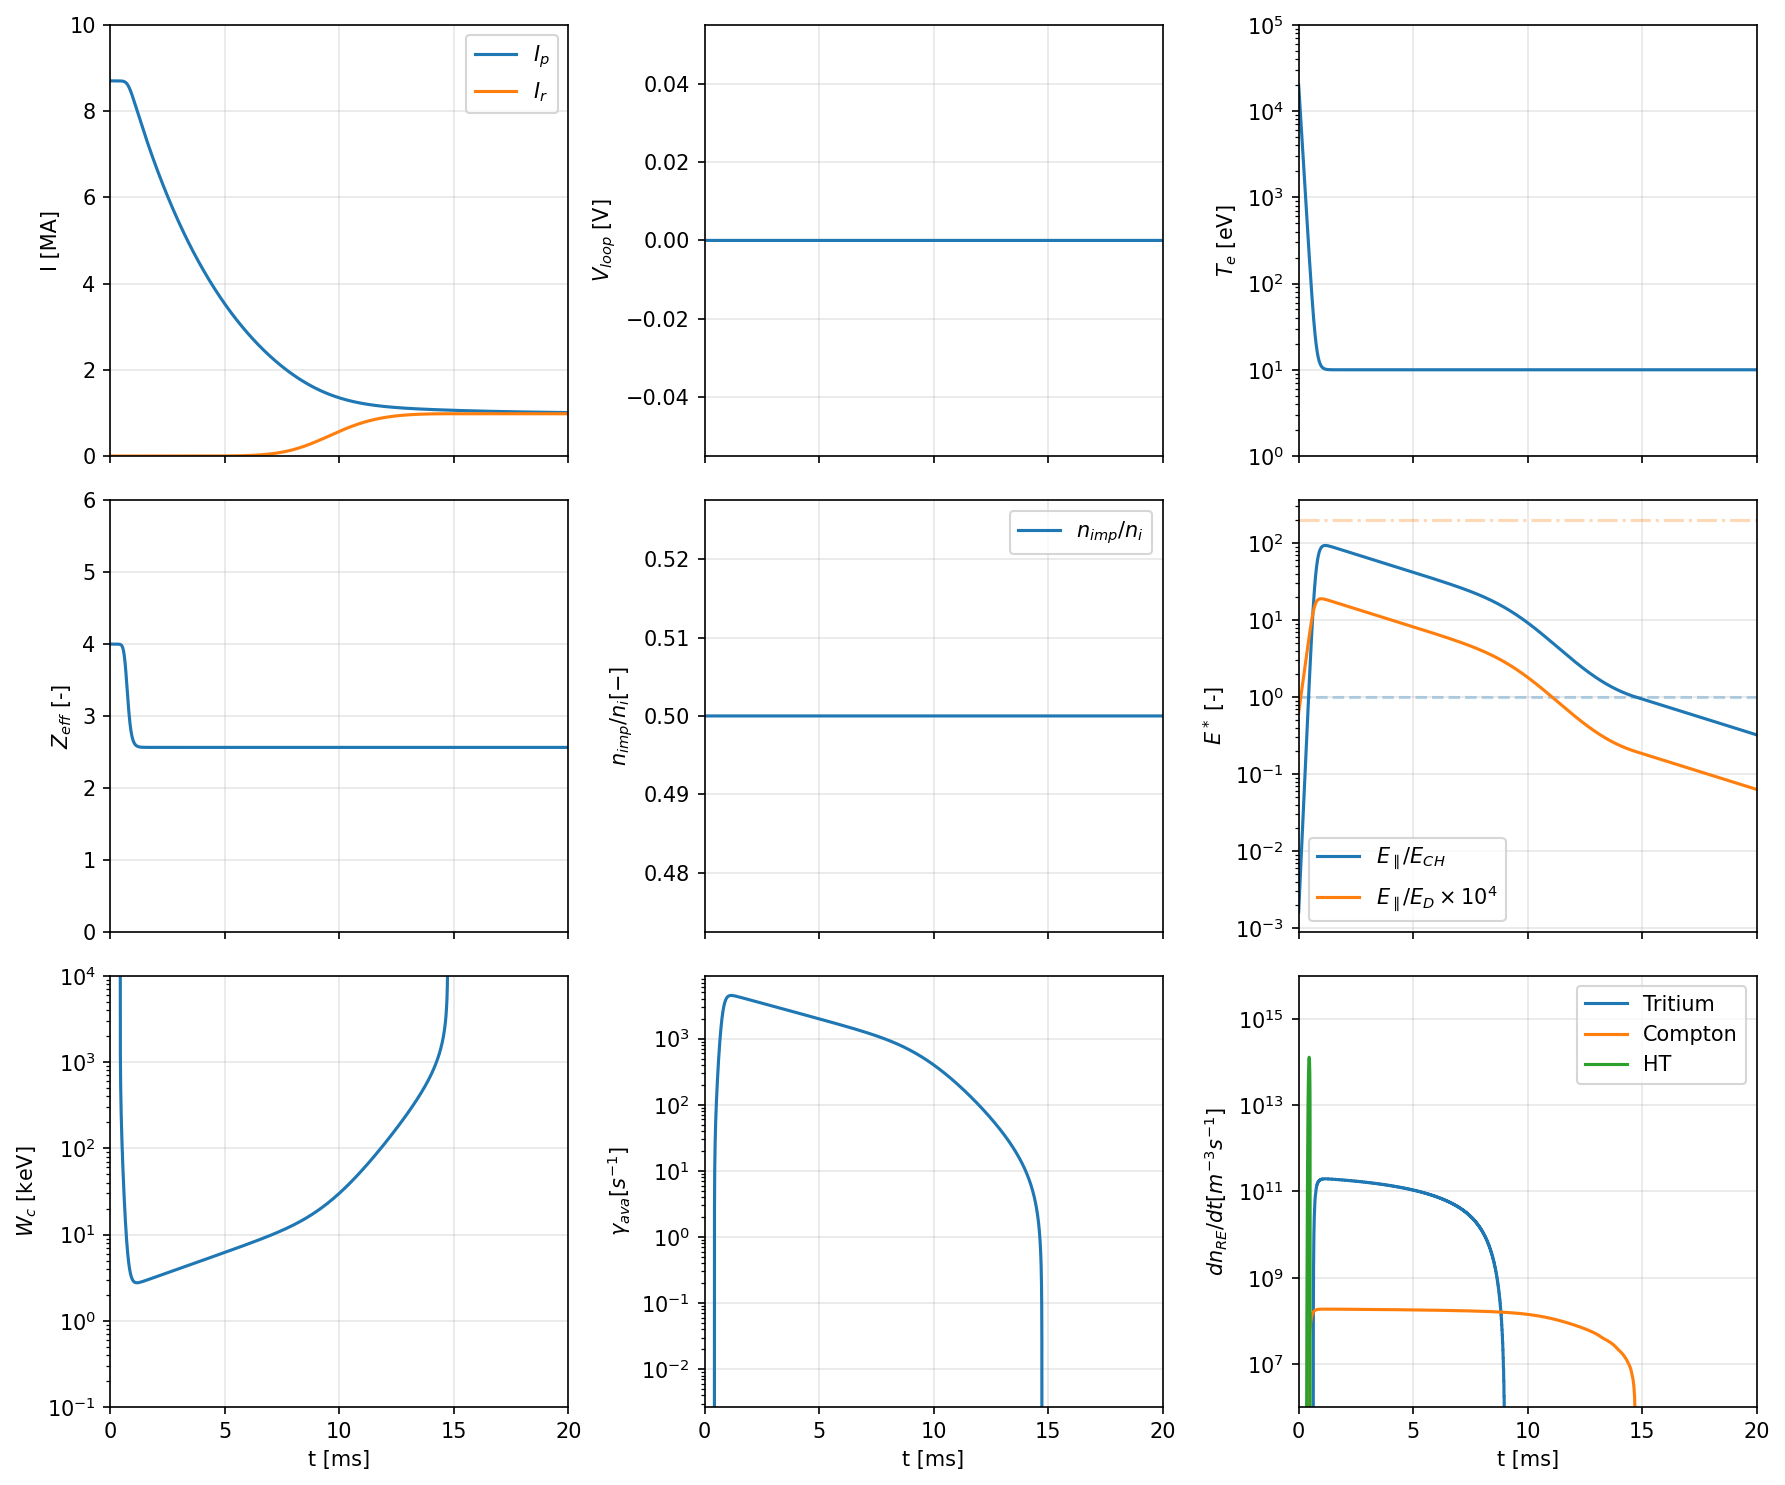

In [13]:
d = solver.diag

fig, axs = plt.subplots(3, 3, sharex=True, figsize=(12, 10), dpi=150)

# ==========================================
# ROW 0: Currents, External Loop Voltage, & Te
# ==========================================
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()
axs[0, 0].set_ylim([0, 10])

axs[0, 1].plot(d['t'] * 1e3, d['Vloop'])
axs[0, 1].set_ylabel('$V_{loop}$ [V]')

axs[0, 2].plot(d['t'] * 1e3, d['Te'])
axs[0, 2].set_ylabel('$T_e$ [eV]')
axs[0, 2].set_ylim([1, 10e4])
axs[0, 2].set_yscale('log')

# ==========================================
# ROW 1: Zeff, Impurities, & E-field
# ==========================================
axs[1, 0].plot(d['t'] * 1e3, d['Zeff'])
axs[1, 0].set_ylabel('$Z_{eff}$ [-]')
axs[1, 0].set_ylim([0, 6])

axs[1, 1].plot(d['t'] * 1e3, d['nimp'] / solver.ni, label='$n_{imp}/n_i$')
axs[1, 1].set_ylabel('$n_{imp}/n_i [-]$')
axs[1, 1].legend()

axs[1, 2].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[1, 2].axhline(1, linestyle='--', alpha=0.3,color='tab:blue')
axs[1, 2].plot(d['t'] * 1e3, d['EoED'] * 1e4, label='$E_\parallel/E_D \\times 10^4$')
axs[1, 2].axhline(2e-2 * 1e4, linestyle='-.', alpha=0.3,color='tab:orange')
axs[1, 2].set_ylabel('$E^*$ [-]')
axs[1, 2].set_yscale('log')
axs[1, 2].legend()

# ==========================================
# ROW 2: Critical Energy & RE Sources
# ==========================================


Wc = RE.getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[2, 0].plot(d['t'] * 1e3, Wc / 1e3)
axs[2, 0].set_ylabel('$W_c$ [keV]')
axs[2, 0].set_yscale('log')
axs[2, 0].set_ylim([1e-1, 1e4])

axs[2, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[2, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[2, 1].set_yscale('log')

# axs[2, 2].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 2].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 2].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 2].plot(d['t'] * 1e3, nht_rate, label='HT')
axs[2, 2].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 2].set_yscale('log')
axs[2, 2].set_ylim([1e6, 1e16])
axs[2, 2].legend()

# ==========================================
# Global Formatting
# ==========================================
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])

# Apply X-axis labels to the bottom row (Row 2)
for ax in axs[2, :]:
    ax.set_xlabel('t [ms]')



fig.set_facecolor('w')
plt.tight_layout()
plt.show()